In [1]:
# ============================================================
# CELDA 1
# Importar librerías
# ============================================================

import pandas as pd
import numpy as np
import plotly.express as px

from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)

In [2]:
# ============================================================
# CELDA 2
# Cargar archivo de estudios primarios
# ============================================================

archivo = "estudios_primarios.csv"

df = pd.read_csv(
    archivo,
    sep=";",
    encoding="utf-8-sig"
)

print("Total de registros:", len(df))
print("Total de columnas:", len(df.columns))

df.head()

Total de registros: 65
Total de columnas: 45


,ID,Autores,Autores APA,Año,Título,País/Región,Fuente,Tipo de publicación,Dominio / contexto,Tipo de sistema,Etapa del ciclo de vida,Fuente de conocimiento,Tipo de conocimiento,Representación del conocimiento,Método computacional,Entrada,Salida,Actividad arquitectónica,Propiedad / objetivo de seguridad,Amenaza / vulnerabilidad,Mecanismo de verificación,Criterios / reglas verificadas,Diseño de evaluación,Dataset / casos de estudio,Línea base / comparación,Métricas,Resultados principales,Mecanismo de refinamiento,Tipo de retroalimentación,Trazabilidad,Explicabilidad,Limitaciones,Brechas / trabajo futuro,RQ1,RQ2,RQ3,RQ4,Calidad / observaciones,DOI / URL,Estado extracción,Completitud,Fecha extracción,Grupo,Revision_manual,Grupo_final
0,1,Philipp Spelten; Morten-Christian Meyer; Anna Wagner; Klaus Wolf; Dirk Reith,Spelten et al.,2024,A Methodology for Integrating Hierarchical VMAP-Data Structures into an Ontology Using Semantically Represented Analyses,Alemania,"Information, 15, 21",Artículo de revista,Gestión de procesos y datos de simulación,Sistema de gestión semántica de datos de simulación / arquitectura de software basada en ontologías,"Diseño arquitectónico, integración y gestión de datos","Especificación industrial VMAP, ontologías de dominio, metadatos de simulación, rutinas de procesamiento y requisitos derivados de casos de uso","Conocimiento de dominio, estructural y procedimental","Ontologías, grafos de conocimiento, RDF/RDFS, OWL y relaciones semánticas","Ontology-Based Data Access (OBDA), población automática de grafos de conocimiento, consultas SPARQL y ejecución de rutinas semánticamente represen...","Archivos VMAP/HDF5, solicitudes de metadatos, ontologías y definiciones de rutinas","Grafo de conocimiento poblado, metadatos recuperados o generados y resultados derivados mediante rutinas de procesamiento","Diseño e implementación de una arquitectura de software para integración, consulta y procesamiento semántico de datos",NaN,NaN,Pruebas funcionales automatizadas del prototipo; no corresponde a verificación de seguridad,"Recuperación de metadatos, detección de duplicados, reutilización de metadatos existentes, ejecución de rutinas y generación de nuevos metadatos","Evaluación mediante prototipo y conjunto de pruebas funcionales, incluyendo un caso industrial de simulación",Archivos VMAP de prueba y caso de moldeo por soplado; parte de los datos industriales no está disponible públicamente,"Comparación de almacenamiento: VMAP 176 kB, STEP AP209 4278 kB y representación OWL 43 652 Kb",Tamaño de almacenamiento y cumplimiento de pruebas funcionales; no se reportan métricas comparativas amplias de rendimiento,"El prototipo automatiza la población del grafo, recupera metadatos mediante consultas semánticas, ejecuta rutinas para generar nuevos metadatos y ...",Bucle opcional de control de versiones para verificar actualización de metadatos y rutinas; refinamiento futuro de las ontologías,Verificación de vigencia/versión de metadatos y rutinas; no se implementa retroalimentación para refinamiento arquitectónico de seguridad,"Sí; relaciones explícitas entre archivos, datasets, metadatos, rutinas, entradas y salidas mediante ontologías y grafos de conocimiento","Parcial; la estructura semántica y las consultas SPARQL permiten inspeccionar relaciones y procedimientos, aunque la explicabilidad no se evalúa e...",Ontologías construidas manualmente; ausencia de un marco ontológico común ampliamente aceptado; prototipo aún no evaluado en explotación industria...,"Automatizar la generación de ontologías, alinear ontologías entre dominios, crear benchmarks SPDM/OBDA, evaluar en escenarios industriales y optim...",Sí,Parcial,No,No,"Evidencia relacionada/transferible. Aporta una implementación clara de conocimiento mediante ontologías y grafos, pero no aborda seguridad ni arqu...",10.3390/info15010021,Completa,100%,25/9/2026,Primario,False,Primario
1,2,Shanxin Sun; Fanchao Meng; Dianhui Chu,Sun et al.,2020,A Model Driven Approach to

In [3]:
# ============================================================
# CELDA 3
# Validación de estudios primarios
# ============================================================

if "Grupo_final" in df.columns:
    
    print(df["Grupo_final"].value_counts(dropna=False))
    
    # Nos aseguramos de trabajar solamente con primarios
    df = df[
        df["Grupo_final"].str.lower() == "primario"
    ].copy()

print("\nEstudios primarios utilizados:", len(df))

Grupo_final
Primario    65
Name: count, dtype: int64

Estudios primarios utilizados: 65


In [4]:
# ============================================================
# CELDA 4
# Limpiar columna Año
# ============================================================

df["Año"] = pd.to_numeric(
    df["Año"],
    errors="coerce"
)

# Verificar si existen años vacíos o incorrectos
print("Valores de Año no válidos:", df["Año"].isna().sum())

# Convertir a entero
df["Año"] = df["Año"].astype("Int64")

print(
    "Periodo analizado:",
    df["Año"].min(),
    "-",
    df["Año"].max()
)

Valores de Año no válidos: 0
Periodo analizado: 2020 - 2026


In [5]:
# ============================================================
# CELDA 5
# Número de estudios por año
# ============================================================

reporte_anual = (
    df.groupby("Año")
      .size()
      .reset_index(name="Estudios")
      .sort_values("Año")
)

# Porcentaje sobre los 65 estudios
reporte_anual["Porcentaje"] = (
    reporte_anual["Estudios"] / len(df) * 100
).round(2)

# Frecuencia acumulada
reporte_anual["Acumulado"] = (
    reporte_anual["Estudios"].cumsum()
)

# Porcentaje acumulado
reporte_anual["Porcentaje acumulado"] = (
    reporte_anual["Acumulado"] / len(df) * 100
).round(2)

display(reporte_anual)

,Año,Estudios,Porcentaje,Acumulado,Porcentaje acumulado
0,2020,5,7.69,5,7.69
1,2021,1,1.54,6,9.23
2,2022,6,9.23,12,18.46
3,2023,4,6.15,16,24.62
4,2024,20,30.77,36,55.38
5,2025,23,35.38,59,90.77
6,2026,6,9.23,65,100.00


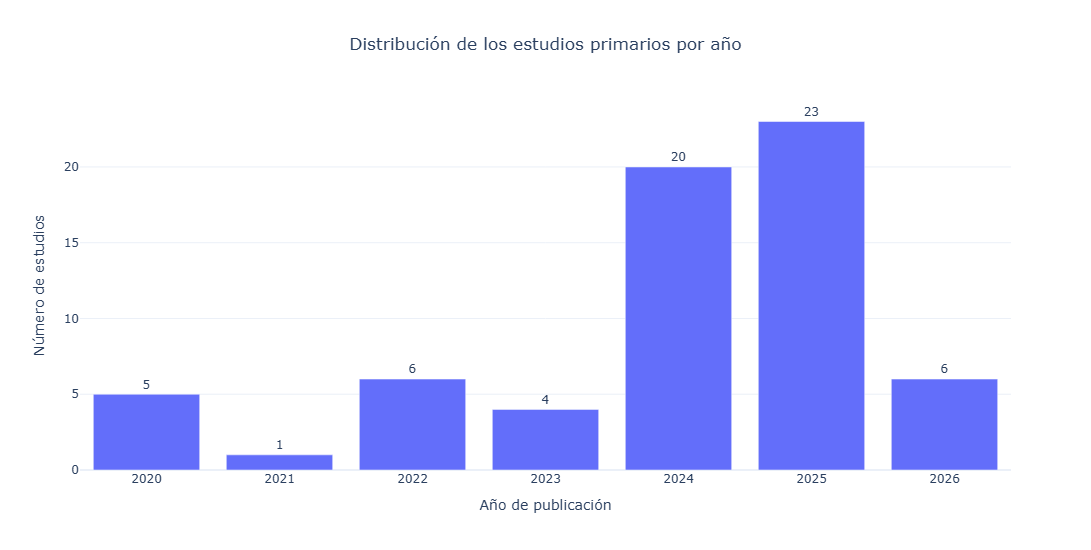

In [6]:
# ============================================================
# CELDA 6
# Gráfico temporal de publicaciones
# ============================================================

fig = px.bar(
    reporte_anual,
    x="Año",
    y="Estudios",
    text="Estudios",
    title="Distribución de los estudios primarios por año",
    labels={
        "Año": "Año de publicación",
        "Estudios": "Número de estudios"
    }
)

fig.update_traces(
    textposition="outside"
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    xaxis=dict(
        tickmode="linear",
        dtick=1
    ),
    yaxis=dict(
        title="Número de estudios"
    ),
    height=550
)

fig.show()

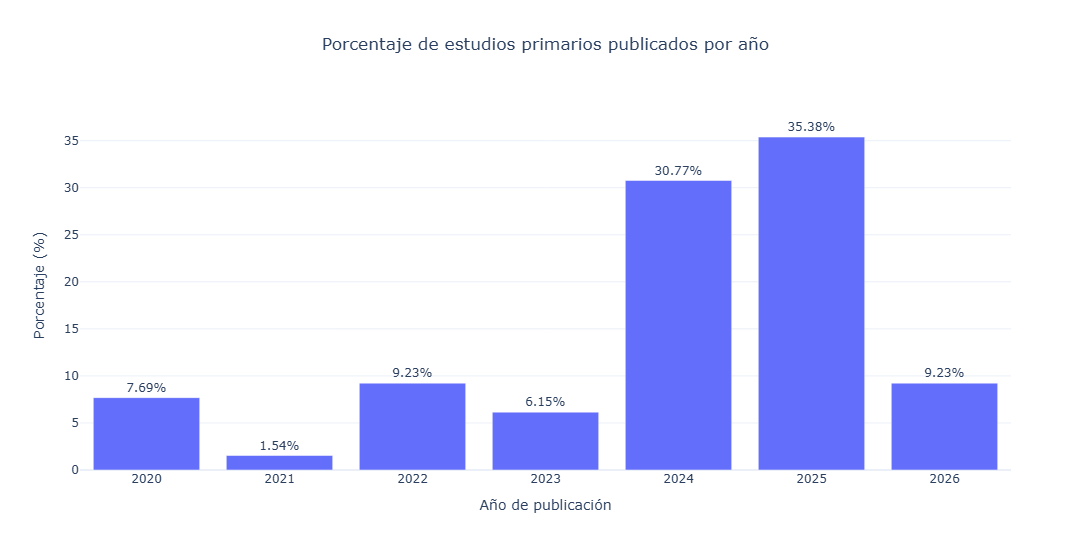

In [7]:
# ============================================================
# CELDA 7
# Gráfico de porcentaje de estudios por año
# ============================================================

fig = px.bar(
    reporte_anual,
    x="Año",
    y="Porcentaje",
    text="Porcentaje",
    title="Porcentaje de estudios primarios publicados por año",
    labels={
        "Año": "Año de publicación",
        "Porcentaje": "Porcentaje (%)"
    }
)

fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside"
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    xaxis=dict(
        tickmode="linear",
        dtick=1
    ),
    height=550
)

fig.show()

In [8]:
# ============================================================
# CELDA 8
# Separar países de estudios multinacionales
# ============================================================

# Conservamos únicamente las columnas necesarias
df_paises = df[
    ["ID", "Año", "Título", "País/Región"]
].copy()

# Dividir los países separados por "/"
df_paises["País"] = (
    df_paises["País/Región"]
    .astype(str)
    .str.split("/")
)

# Convertir cada país en una fila independiente
df_paises = df_paises.explode("País")

# Limpiar espacios
df_paises["País"] = (
    df_paises["País"]
    .str.strip()
)

display(df_paises.head(15))

,ID,Año,Título,País/Región,País
0,1,2024,A Methodology for Integrating Hierarchical VMAP-Data Structures into an Ontology Using Semantically Represented Analyses,Alemania,Alemania
1,2,2020,A Model Driven Approach to Constructing Knowledge Graph from Relational Database,China,China
2,3,2026,A model-driven knowledge graph treatment for process-centric cyber threat mitigation,Rumania,Rumania
3,4,2025,"Aligning DevOps and Microservice Architecture: Empirical Mapping, Taxonomy, and RAG-Based Decision Support",Iran,Iran
4,6,2026,An Empirical Evaluation of Large Language Models Applying Software Architectural Patterns,Grecia,Grecia
5,8,2020,An ontology-based learning approach for automatically classifying security requirements,China,China
6,9,2024,An ontology-based secure design framework for graph-based databases,España,España
7,10,2026,Automated regulatory compliance for AI systems in the security domain: The case of dual-use deployment,Lituania,Lituania
8,11,2020,Understanding and recommending security requirements from problem domain ontology: A cognitive three-layered approach,Corea del Sur,Corea del Sur
9,13,2026,CONSENT: A Software Architecture for Dynamic and Secure Consent Management,Grecia,Grecia


In [9]:
# ============================================================
# CELDA 9
# Normalización de países
# ============================================================

normalizacion_paises = {
    
    "Irán": "Iran",
    "Iran": "Iran",
    
    "República de Corea": "Corea del Sur",
    "Corea del Sur": "Corea del Sur",
    
    "Türkiye": "Turquía",
    "Turquía": "Turquía"
}

df_paises["País"] = df_paises["País"].replace(
    normalizacion_paises
)

print(
    "Número de países diferentes:",
    df_paises["País"].nunique()
)

Número de países diferentes: 29


In [10]:
# ============================================================
# CELDA 10
# Conteo de estudios por país
#
# Se utiliza conteo completo:
# un estudio internacional cuenta para cada país participante.
# ============================================================

reporte_paises = (
    df_paises.groupby("País")["ID"]
    .nunique()
    .reset_index(name="Estudios")
    .sort_values(
        "Estudios",
        ascending=False
    )
)

# Porcentaje respecto a los 65 estudios
reporte_paises["Porcentaje"] = (
    reporte_paises["Estudios"] / len(df) * 100
).round(2)

reporte_paises = reporte_paises.reset_index(drop=True)

display(reporte_paises)

,País,Estudios,Porcentaje
0,China,23,35.38
1,Francia,4,6.15
2,India,4,6.15
3,Arabia Saudita,3,4.62
4,Estados Unidos,3,4.62
5,Corea del Sur,3,4.62
6,Rumania,3,4.62
7,Italia,3,4.62
8,Alemania,3,4.62
9,Grecia,2,3.08


In [11]:
# ============================================================
# CELDA 11
# Tabla completa de países
# ============================================================

display(
    reporte_paises.style
    .format({
        "Porcentaje": "{:.2f}%"
    })
)

,País,Estudios,Porcentaje
0,China,23,35.38%
1,Francia,4,6.15%
2,India,4,6.15%
3,Arabia Saudita,3,4.62%
4,Estados Unidos,3,4.62%
5,Corea del Sur,3,4.62%
6,Rumania,3,4.62%
7,Italia,3,4.62%
8,Alemania,3,4.62%
9,Grecia,2,3.08%


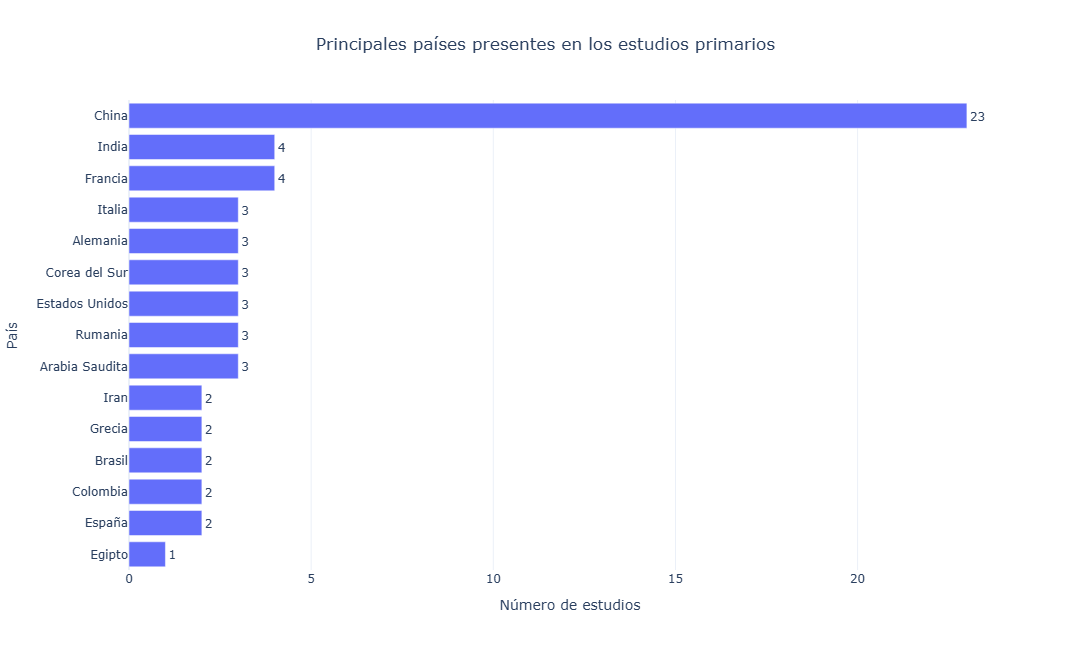

In [12]:
# ============================================================
# CELDA 12
# Gráfico de países con mayor número de estudios
# ============================================================

top_paises = reporte_paises.head(15).copy()

fig = px.bar(
    top_paises.sort_values("Estudios"),
    x="Estudios",
    y="País",
    orientation="h",
    text="Estudios",
    title="Principales países presentes en los estudios primarios",
    labels={
        "Estudios": "Número de estudios",
        "País": "País"
    }
)

fig.update_traces(
    textposition="outside"
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=650
)

fig.show()

In [13]:
# ============================================================
# CELDA 13
# Diccionario ISO-3 para los países encontrados
# ============================================================

iso3 = {
    "Alemania": "DEU",
    "Arabia Saudita": "SAU",
    "Australia": "AUS",
    "Austria": "AUT",
    "Brasil": "BRA",
    "China": "CHN",
    "Colombia": "COL",
    "Corea del Sur": "KOR",
    "Egipto": "EGY",
    "España": "ESP",
    "Estados Unidos": "USA",
    "Francia": "FRA",
    "Grecia": "GRC",
    "India": "IND",
    "Iran": "IRN",
    "Irlanda": "IRL",
    "Italia": "ITA",
    "Líbano": "LBN",
    "Lituania": "LTU",
    "Malasia": "MYS",
    "Pakistán": "PAK",
    "Portugal": "PRT",
    "Reino Unido": "GBR",
    "Rumania": "ROU",
    "Rusia": "RUS",
    "Taiwán": "TWN",
    "Turquía": "TUR",
    "Ucrania": "UKR",
    "Vietnam": "VNM"
}

reporte_paises["ISO3"] = reporte_paises["País"].map(iso3)

display(reporte_paises.head())

,País,Estudios,Porcentaje,ISO3
0,China,23,35.38,CHN
1,Francia,4,6.15,FRA
2,India,4,6.15,IND
3,Arabia Saudita,3,4.62,SAU
4,Estados Unidos,3,4.62,USA


In [14]:
# ============================================================
# CELDA 14
# Comprobar países sin código ISO
# ============================================================

sin_iso = reporte_paises[
    reporte_paises["ISO3"].isna()
]

if len(sin_iso) == 0:
    print("✓ Todos los países tienen código ISO-3.")
else:
    print("⚠ Existen países sin código ISO:")
    display(sin_iso)

✓ Todos los países tienen código ISO-3.


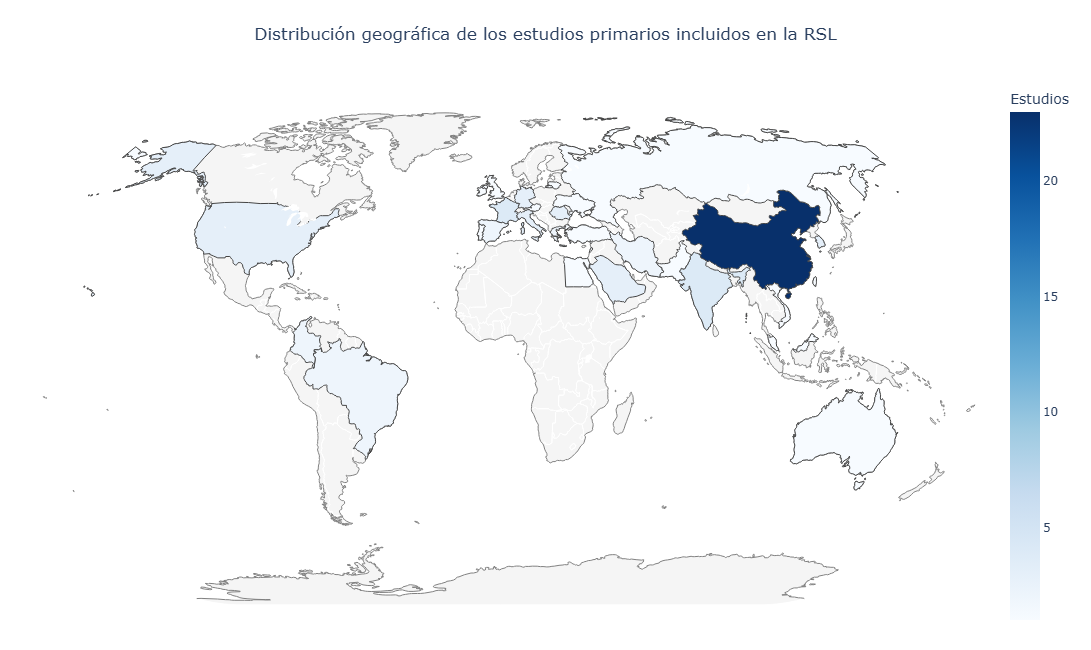

In [15]:
# ============================================================
# CELDA 15
# Mapa mundial de los estudios primarios
# América ubicada al lado izquierdo
# ============================================================

fig_mapa = px.choropleth(
    reporte_paises,
    
    locations="ISO3",
    color="Estudios",
    hover_name="País",
    
    hover_data={
        "ISO3": False,
        "Estudios": True,
        "Porcentaje": True
    },
    
    color_continuous_scale="Blues",
    
    title=(
        "Distribución geográfica de los estudios primarios "
        "incluidos en la RSL"
    ),
    
    labels={
        "Estudios": "Estudios",
        "Porcentaje": "Porcentaje (%)"
    }
)

# ------------------------------------------------------------
# Configuración geográfica
#
# rotation.lon = 0 mantiene:
# América     -> izquierda
# Europa      -> centro
# Asia        -> derecha
# ------------------------------------------------------------

fig_mapa.update_geos(
    
    projection=dict(
        type="natural earth",
        rotation=dict(
            lon=0,
            lat=0,
            roll=0
        )
    ),
    
    showcoastlines=True,
    coastlinecolor="gray",
    
    showland=True,
    landcolor="rgb(245,245,245)",
    
    showcountries=True,
    countrycolor="white",
    
    showframe=False
)

fig_mapa.update_layout(
    
    template="plotly_white",
    
    title=dict(
        x=0.5,
        xanchor="center"
    ),
    
    height=650,
    
    margin=dict(
        l=20,
        r=20,
        t=80,
        b=20
    ),
    
    coloraxis_colorbar=dict(
        title="Estudios"
    )
)

fig_mapa.show()

In [16]:
# ============================================================
# CELDA 16
# Clasificar intensidad de producción
# ============================================================

def categoria_estudios(n):
    
    if n == 1:
        return "1 estudio"
    
    elif n <= 3:
        return "2-3 estudios"
    
    elif n <= 5:
        return "4-5 estudios"
    
    elif n <= 10:
        return "6-10 estudios"
    
    else:
        return "Más de 10 estudios"


reporte_paises["Nivel"] = (
    reporte_paises["Estudios"]
    .apply(categoria_estudios)
)

display(
    reporte_paises[
        ["País", "Estudios", "Nivel"]
    ]
)

,País,Estudios,Nivel
0,China,23,Más de 10 estudios
1,Francia,4,4-5 estudios
2,India,4,4-5 estudios
3,Arabia Saudita,3,2-3 estudios
4,Estados Unidos,3,2-3 estudios
5,Corea del Sur,3,2-3 estudios
6,Rumania,3,2-3 estudios
7,Italia,3,2-3 estudios
8,Alemania,3,2-3 estudios
9,Grecia,2,2-3 estudios


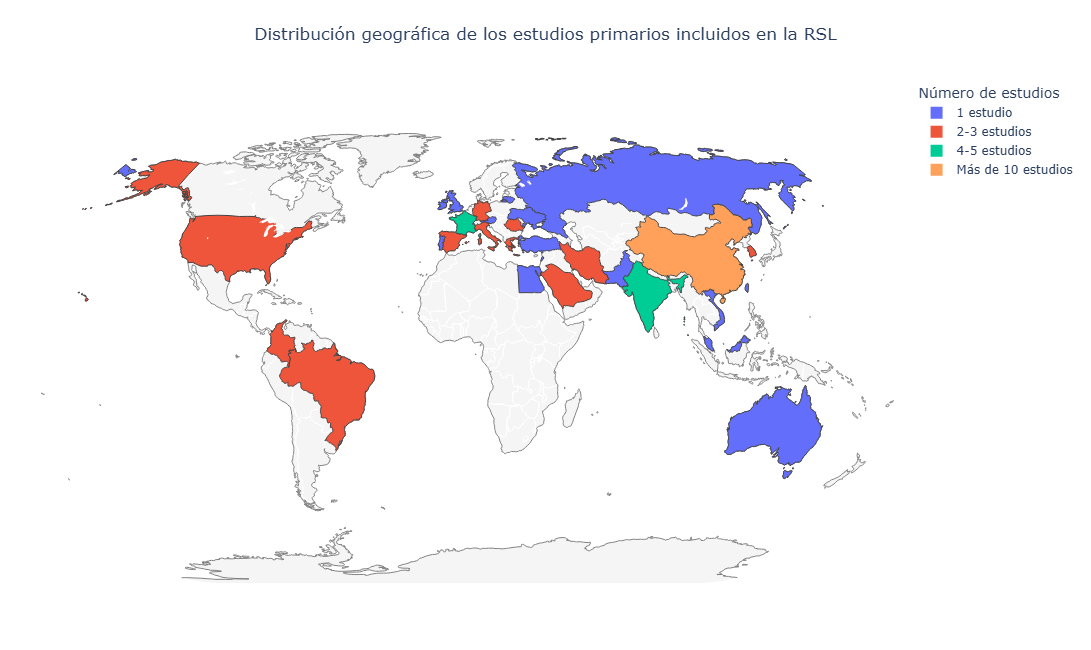

In [17]:
# ============================================================
# CELDA 17
# Mapa mundial por categorías
# América ubicada al lado izquierdo
# ============================================================

fig = px.choropleth(
    
    reporte_paises,
    
    locations="ISO3",
    color="Nivel",
    
    hover_name="País",
    
    hover_data={
        "ISO3": False,
        "Estudios": True
    },
    
    category_orders={
        "Nivel": [
            "1 estudio",
            "2-3 estudios",
            "4-5 estudios",
            "6-10 estudios",
            "Más de 10 estudios"
        ]
    },
    
    title=(
        "Distribución geográfica de los estudios primarios "
        "incluidos en la RSL"
    )
)

# ------------------------------------------------------------
# Configuración del mapa
# rotation.lon = 0:
# América a la izquierda y Asia a la derecha
# ------------------------------------------------------------

fig.update_geos(
    
    projection=dict(
        type="natural earth",
        rotation=dict(
            lon=0,
            lat=0,
            roll=0
        )
    ),
    
    showcountries=True,
    countrycolor="white",
    
    showcoastlines=True,
    coastlinecolor="gray",
    
    showland=True,
    landcolor="rgb(245,245,245)",
    
    showframe=False
)

fig.update_layout(
    
    template="plotly_white",
    
    title=dict(
        x=0.5,
        xanchor="center"
    ),
    
    height=650,
    
    margin=dict(
        l=20,
        r=20,
        t=80,
        b=20
    ),
    
    legend_title_text="Número de estudios"
)

fig.show()

In [18]:
# ============================================================
# CELDA 20
# Resumen estadístico automático para la RSL
# ============================================================

total = len(df)

anio_mayor = reporte_anual.loc[
    reporte_anual["Estudios"].idxmax()
]

pais_mayor = reporte_paises.iloc[0]

estudios_2024_2025 = reporte_anual[
    reporte_anual["Año"].isin([2024, 2025])
]["Estudios"].sum()

porcentaje_2024_2025 = (
    estudios_2024_2025 / total * 100
)

print("RESUMEN DE RESULTADOS")
print("-" * 60)

print(
    f"Se analizaron {total} estudios primarios "
    f"publicados entre {df['Año'].min()} y {df['Año'].max()}."
)

print(
    f"El año con mayor número de publicaciones fue "
    f"{int(anio_mayor['Año'])}, con "
    f"{int(anio_mayor['Estudios'])} estudios "
    f"({anio_mayor['Porcentaje']:.2f}%)."
)

print(
    f"Los años 2024 y 2025 concentran "
    f"{estudios_2024_2025} estudios, equivalentes al "
    f"{porcentaje_2024_2025:.2f}% del total."
)

print(
    f"El país con mayor presencia es "
    f"{pais_mayor['País']}, con "
    f"{pais_mayor['Estudios']} estudios."
)

print(
    f"En total se identificaron "
    f"{reporte_paises['País'].nunique()} países."
)

print(
    f"Se registraron "
    f"{reporte_paises['Estudios'].sum()} participaciones "
    f"nacionales considerando los estudios multinacionales."
)

RESUMEN DE RESULTADOS
------------------------------------------------------------
Se analizaron 65 estudios primarios publicados entre 2020 y 2026.
El año con mayor número de publicaciones fue 2025, con 23 estudios (35.38%).
Los años 2024 y 2025 concentran 43 estudios, equivalentes al 66.15% del total.
El país con mayor presencia es China, con 23 estudios.
En total se identificaron 29 países.
Se registraron 74 participaciones nacionales considerando los estudios multinacionales.
